https://github.com/bmoscon/cryptofeed

In [1]:
import pandas as pd
from market_data_real import MarketDataCollector

In [2]:
collector = MarketDataCollector(
    markets=[
        (
            "BINANCE",
            "BTC-USDT"
        ),
        (
            "HYPERLIQUID",
            "BTC-USD-PERP"
        ),
    ],

    record_raw=True,
)

In [8]:
await collector.collect(900)

Added BINANCE BTC-USDT
Added HYPERLIQUID BTC-USD-PERP

Started 2 market(s).
Raw PCAP directory: data/raw/pcap/20260927T112551_405040Z
Stopping feeds...
Flushing Parquet storage...
Stopped.


In [13]:
books_hyper_raw= pd.read_parquet("data/raw/normalised/HYPERLIQUID/BTC-USD-PERP/book")
books_bin_raw = pd.read_parquet("data/raw/normalised/BINANCE/BTC-USDT/book")

In [66]:
books_bin = books_bin.dropna()
books_bin['exchange_timestamp'] = pd.to_datetime(books_bin['exchange_timestamp'], utc=True, unit = 's').dt.tz_convert('Australia/Sydney')
books_bin = books_bin.set_index('exchange_timestamp')
books_bin.tail()

,exchange,symbol,bid,bid_size,ask,ask_size,mid,spread,spread_bps,imbalance,microprice,receipt_timestamp
exchange_timestamp,,,,,,,,,,,,
2026-09-27 18:14:40.914000034+10:00,BINANCE,BTC-USDT,84803.99,3.37345,84804.0,5.01307,84803.995,0.01,0.001179,-0.195507,84803.994022,1.790497e+09
2026-09-27 18:14:41.013999939+10:00,BINANCE,BTC-USDT,84803.99,3.37345,84804.0,3.74835,84803.995,0.01,0.001179,-0.052641,84803.994737,1.790497e+09
2026-09-27 18:14:41.114000082+10:00,BINANCE,BTC-USDT,84803.99,3.82534,84804.0,3.74835,84803.995,0.01,0.001179,0.010165,84803.995051,1.790497e+09
2026-09-27 18:14:41.213999987+10:00,BINANCE,BTC-USDT,84803.99,3.82534,84804.0,3.74835,84803.995,0.01,0.001179,0.010165,84803.995051,1.790497e+09
2026-09-27 18:14:41.313999891+10:00,BINANCE,BTC-USDT,84803.99,3.82569,84804.0,3.74835,84803.995,0.01,0.001179,0.010211,84803.995051,1.790497e+09


In [61]:
from datetime import datetime, timezone
from zoneinfo import ZoneInfo

In [85]:
books_hyper_raw = pd.read_parquet("data/raw/normalised/HYPERLIQUID/BTC-USD-PERP")

In [80]:
books_hyper = books_hyper.dropna()
books_hyper['exchange_timestamp'] = pd.to_datetime(books_hyper['exchange_timestamp'], utc=True, unit = 's').dt.tz_convert('Australia/Sydney')
books_hyper = books_hyper.set_index('exchange_timestamp')
books_hyper.tail()

,exchange,symbol,bid,bid_size,ask,ask_size,mid,spread,spread_bps,imbalance,microprice,receipt_timestamp
exchange_timestamp,,,,,,,,,,,,
2026-09-27 18:14:19.368000031+10:00,HYPERLIQUID,BTC-USD-PERP,84795.0,1.39860,84796.0,9.13901,84795.5,1.0,0.117931,-0.734551,84795.132725,1.790497e+09
2026-09-27 18:14:24.325000048+10:00,HYPERLIQUID,BTC-USD-PERP,84795.0,0.02029,84796.0,11.02179,84795.5,1.0,0.117931,-0.996325,84795.001838,1.790497e+09
2026-09-27 18:14:29.684000015+10:00,HYPERLIQUID,BTC-USD-PERP,84789.0,3.24420,84790.0,6.06625,84789.5,1.0,0.117939,-0.303106,84789.348447,1.790497e+09
2026-09-27 18:14:35.088000059+10:00,HYPERLIQUID,BTC-USD-PERP,84789.0,3.52666,84790.0,6.96541,84789.5,1.0,0.117939,-0.327748,84789.336126,1.790497e+09
2026-09-27 18:14:40.466000080+10:00,HYPERLIQUID,BTC-USD-PERP,84789.0,4.25813,84790.0,6.20354,84789.5,1.0,0.117939,-0.185956,84789.407022,1.790497e+09


In [92]:
books_hyper.columns

Index(['exchange', 'symbol', 'bid', 'bid_size', 'ask', 'ask_size', 'mid',
       'spread', 'spread_bps', 'imbalance', 'microprice', 'receipt_timestamp'],
      dtype='str')

resampled to 100ms

In [14]:
b = books_bin_raw.copy()

b["datetime"] = pd.to_datetime(
    b["receipt_timestamp"],
    unit="s",
    utc=True
)

b = (
    b
    .set_index("datetime")
    .sort_index()
)

In [15]:
h = books_hyper_raw.copy()

h["datetime"] = pd.to_datetime(
    h["receipt_timestamp"],
    unit="s",
    utc=True
)

h = (
    h
    .set_index("datetime")
    .sort_index()
)

In [32]:
b_100ms = (
    b[["mid"]]
    .resample("100ms")
    .last()
    .ffill()
    .rename(columns={"mid": "binance_mid"})
)

h_100ms = (
    h[["mid"]]
    .resample("100ms")
    .last()
    .ffill()
    .rename(columns={"mid": "hyperliquid_mid"})
)

In [33]:
df = b_100ms.join(
    h_100ms,
    how="inner"
)

<Axes: title={'center': 'Hyperliquid - Binance BTC Mid Difference (bps)'}, xlabel='datetime'>

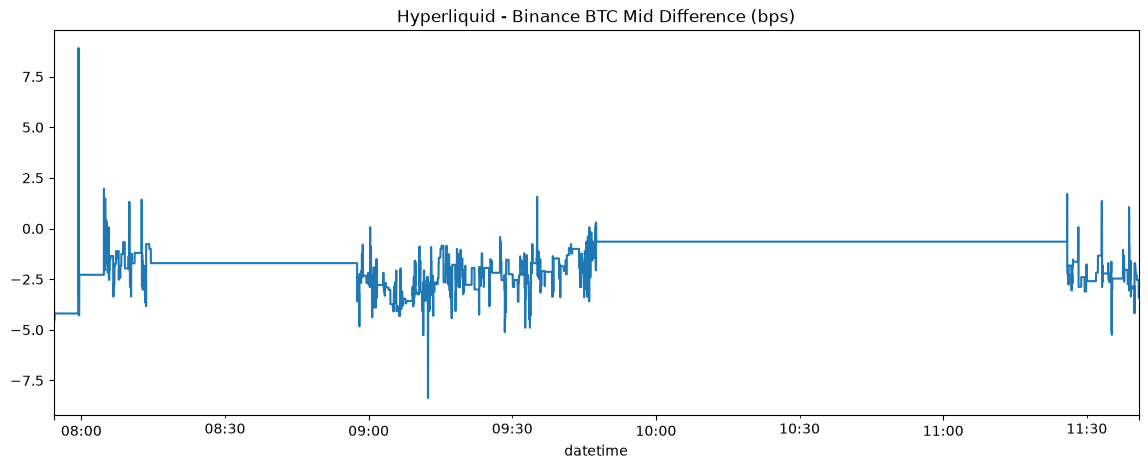

In [34]:
df["mid_diff"] = (
    df["hyperliquid_mid"]
    - df["binance_mid"]
)

df["reference_mid"] = (
    df["hyperliquid_mid"]
    + df["binance_mid"]
) / 2

df["mid_diff_bps"] = (
    df["hyperliquid_mid"]
    - df["binance_mid"]
) / df["reference_mid"] * 10_000

df["mid_diff_bps"].plot(
    figsize=(14, 5),
    title="Hyperliquid - Binance BTC Mid Difference (bps)"
)

<Axes: xlabel='datetime'>

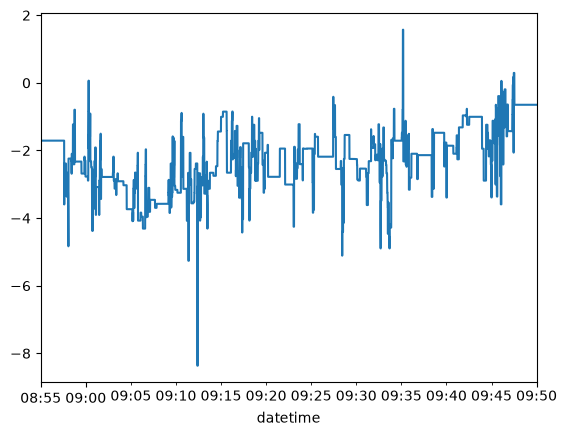

In [42]:
middle_session = df.loc[
    "2026-09-27 08:55:00+00:00":
    "2026-09-27 09:50:00+00:00"
]

middle_session['mid_diff_bps'].plot()

In [45]:
middle_session

,binance_mid,hyperliquid_mid,mid_diff,reference_mid,mid_diff_bps,ema
datetime,,,,,,
2026-09-27 08:55:00+00:00,84803.995,84789.5,-14.495,84796.7475,-1.709382,-14.495
2026-09-27 08:55:00.100000+00:00,84803.995,84789.5,-14.495,84796.7475,-1.709382,-14.495
2026-09-27 08:55:00.200000+00:00,84803.995,84789.5,-14.495,84796.7475,-1.709382,-14.495
2026-09-27 08:55:00.300000+00:00,84803.995,84789.5,-14.495,84796.7475,-1.709382,-14.495
2026-09-27 08:55:00.400000+00:00,84803.995,84789.5,-14.495,84796.7475,-1.709382,-14.495
...,...,...,...,...,...,...
2026-09-27 09:50:00.500000+00:00,84886.005,84880.5,-5.505,84883.2525,-0.648538,-5.505
2026-09-27 09:50:00.600000+00:00,84886.005,84880.5,-5.505,84883.2525,-0.648538,-5.505
2026-09-27 09:50:00.700000+00:00,84886.005,84880.5,-5.505,84883.2525,-0.648538,-5.505


In [48]:
import plotly.express as px

<Axes: xlabel='datetime'>

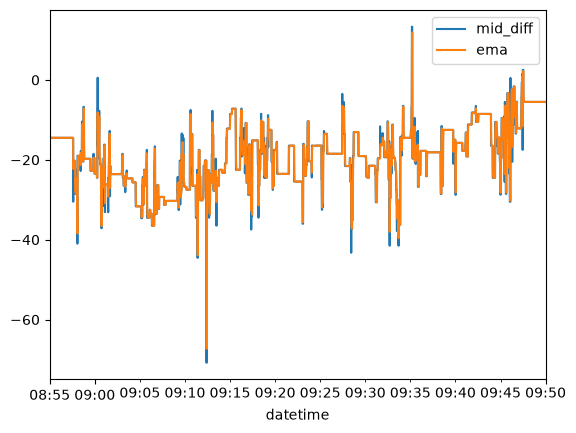

In [46]:
middle_session['ema'] = middle_session['mid_diff'].ewm(span = 21, adjust = False).mean()
middle_session[['mid_diff', 'ema']].plot()

In [54]:
fig = px.line(
    middle_session.reset_index(), 
    x="datetime", 
    y=["mid_diff", "ema"],  # Removed the outer square brackets
    title="Hyperliquid - Binance BTC Mid Difference (bps)"
)

fig.show()

In trying to decompose the above ema into different components (using orderflow, orderbook data and whatever else using bayesian methods) to try and uncover an 'efficient price', how would you know if it's efficient or not? What would a more 'efficient' price give/show that a normal EMA can't? 

- Would it be less susceptible to adverse fills? 
- Would a more efficient fair value increase or decrease fills conditional on a regime?
- In essence, what would an efficient price even look like?

In [30]:
df_copy = df.sort_values("datetime").copy()
df_copy = df_copy.reset_index()
# Anything more than 5 seconds apart = new collection session
df_copy["session"] = (
    df_copy["datetime"]
    .diff()
    .gt(pd.Timedelta("30m"))
    .cumsum()
)

df_copy

,datetime,binance_mid,hyperliquid_mid,mid_diff,reference_mid,mid_diff_bps,session
0,2026-09-27 07:54:13.700000+00:00,84661.825,84635.5,-26.325,84648.6625,-3.109913,0
1,2026-09-27 07:54:13.800000+00:00,84661.825,84635.5,-26.325,84648.6625,-3.109913,0
2,2026-09-27 07:54:13.900000+00:00,84661.825,84635.5,-26.325,84648.6625,-3.109913,0
3,2026-09-27 07:54:14+00:00,84661.825,84635.5,-26.325,84648.6625,-3.109913,0
4,2026-09-27 07:54:14.100000+00:00,84661.825,84635.5,-26.325,84648.6625,-3.109913,0
...,...,...,...,...,...,...,...
135961,2026-09-27 11:40:49.800000+00:00,84868.385,84839.5,-28.885,84853.9425,-3.404085,0
135962,2026-09-27 11:40:49.900000+00:00,84868.385,84839.5,-28.885,84853.9425,-3.404085,0
135963,2026-09-27 11:40:50+00:00,84868.385,84839.5,-28.885,84853.9425,-3.404085,0
135964,2026-09-27 11:40:50.100000+00:00,84868.385,84839.5,-28.885,84853.9425,-3.404085,0


In [31]:
stitched = (
    df
    .sort_values(["session", "datetime"])
    .reset_index(drop=True)
)

stitched["sample"] = range(len(stitched))

KeyError: 'session'